I'm comparing five NBA's players

I want to rate their "all-around impact"

I'm using career + last season

I'm building ranking + score

In [15]:
from nba_api.stats.static import teams, players
import pandas as pd
from nba_api.stats.endpoints import *


nba_players = players.get_players()

players_df = pd.DataFrame(nba_players)

LebronJames = players_df[players_df['full_name'] == 'LeBron James']
StephenCurry = players_df[players_df['full_name'] == 'Stephen Curry']
LukaDoncic = players_df[players_df['full_name'] == 'Luka Doncic']
GiannisAntetokounmpo = players_df[players_df['full_name'] == 'Giannis Antetokounmpo']
NikolaJokic = players_df[players_df['full_name'] == 'Nikola Jokic']

LebronJames_id = LebronJames['id'].iloc[0]
# print(LebronJames_id)

LJ_career = playercareerstats.PlayerCareerStats(player_id=LebronJames_id)

df = LJ_career.get_data_frames()[0]

df['PPG'] = df['PTS'] / df['GP']
df['APG'] = df['AST'] / df['GP']
df['RPG'] = df['REB'] / df['GP']

career_ppg = df['PTS'].sum() / df['GP'].sum()
career_apg = df['AST'].sum() / df['GP'].sum()
career_rpg = df['REB'].sum() / df['GP'].sum()

df_columns = df[['SEASON_ID', 'GP', 'PTS', 'PPG', 'APG', 'RPG']]

print(career_ppg)
print(career_apg)
print(career_rpg)

26.781750924784216
7.408138101109741
7.4568434032059185


In [16]:
from nba_api.stats.static import teams, players
import pandas as pd
from nba_api.stats.endpoints import *

nba_players = players.get_players()

players_df = pd.DataFrame(nba_players)

def get_career_stats(player_id):

    Player = playercareerstats.PlayerCareerStats(player_id=player_id)
    df = Player.get_data_frames()[0]

    df['PPG'] = df['PTS'] / df['GP']
    df['APG'] = df['AST'] / df['GP']
    df['RPG'] = df['REB'] / df['GP']

    return df[['SEASON_ID', 'GP', 'PTS', 'PPG', 'APG', 'RPG', 'MIN']]

def get_player_id(name):
    player = players_df[players_df['full_name'].str.lower().str.contains(name.lower(), na=False)]
    return player['id'].iloc[0]


# lebron_id = get_player_id("LeBron James")
# df = get_career_stats(lebron_id)
# df

names = ['LeBron James', 'Stephen Curry', 'Luka Dončić', 'Giannis Antetokounmpo', 'Nikola Jokić']

results = []

for name in names:
    player_id = get_player_id(name)

    Player = playercareerstats.PlayerCareerStats(player_id=player_id)
    df = Player.get_data_frames()[0]

    results.append({
        "Player": name,
        "PPG": df['PTS'].sum() / df['GP'].sum(),
        "APG": df['AST'].sum() / df['GP'].sum(),
        "RPG": df['REB'].sum() / df['GP'].sum()
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='PPG', ascending=False)
results_df['PPG_rank'] = results_df['PPG'].rank(ascending=False).astype(int)
results_df['AST_rank'] = results_df['APG'].rank(ascending=False).astype(int)
results_df['AST_TO_PTS'] = results_df['APG'] / results_df['PPG']
results_df


,Player,PPG,APG,RPG,PPG_rank,AST_rank,AST_TO_PTS
2,Luka Dončić,29.129433,8.179078,8.484043,1,1,0.280784
0,LeBron James,26.781751,7.408138,7.456843,2,3,0.276611
1,Stephen Curry,24.815716,6.307764,4.652011,3,4,0.254184
3,Giannis Antetokounmpo,24.056983,5.010056,9.924022,4,5,0.208258
4,Nikola Jokić,22.233333,7.506173,11.082716,5,2,0.337609


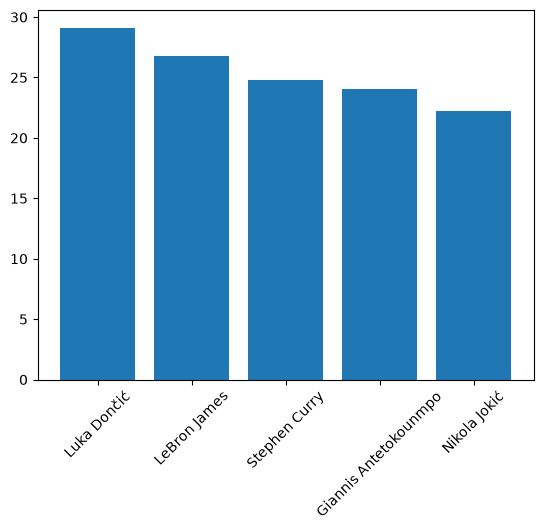

In [17]:
import matplotlib.pyplot as plt

plt.bar(results_df['Player'], results_df['PPG'])
plt.xticks(rotation=45)
plt.show()

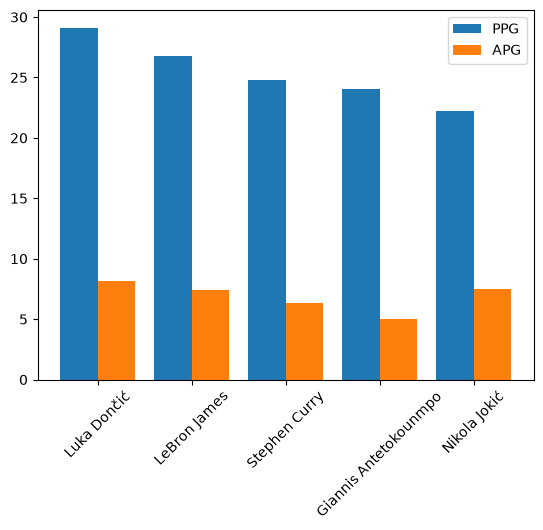

In [22]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = results_df[['Player', 'PPG', 'APG']]


x = np.arange(len(plot_df['Player']))

plt.bar(x - 0.2, plot_df['PPG'], width=0.4, label='PPG')
plt.bar(x + 0.2, plot_df['APG'], width=0.4, label='APG')

plt.xticks(x, plot_df['Player'], rotation=45)
plt.legend()
plt.show()

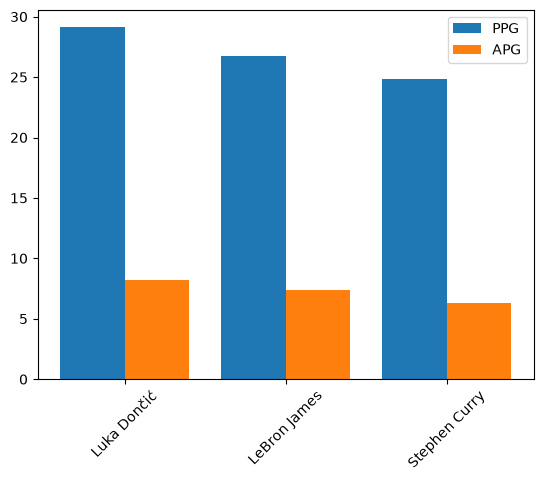

In [27]:
top_players_df = results_df.sort_values(by='PPG', ascending=False).head(3)

plot_df = top_players_df[['Player', 'PPG', 'APG']]

x = np.arange(len(top_players_df['Player']))

plt.bar(x - 0.2, plot_df['PPG'], width=0.4, label='PPG')
plt.bar(x + 0.2, plot_df['APG'], width=0.4, label='APG')

plt.xticks(x, plot_df['Player'], rotation=45)
plt.legend()
plt.show()

In [26]:
results_df['ALL_AROUND_SCORE'] = (
    results_df['PPG'] * 0.5 +
    results_df['APG'] * 0.3 +
    results_df['RPG'] * 0.2
)

results_df = results_df.sort_values(by='ALL_AROUND_SCORE', ascending=False)
results_df['MVP_rank'] = results_df['ALL_AROUND_SCORE'].rank(ascending=False).astype(int)

results_df[['Player', 'PPG', 'APG', 'RPG', 'ALL_AROUND_SCORE', 'MVP_rank']]

,Player,PPG,APG,RPG,ALL_AROUND_SCORE,MVP_rank
2,Luka Dončić,29.129433,8.179078,8.484043,18.715248,1
0,LeBron James,26.781751,7.408138,7.456843,17.104686,2
4,Nikola Jokić,22.233333,7.506173,11.082716,15.585062,3
3,Giannis Antetokounmpo,24.056983,5.010056,9.924022,15.516313,4
1,Stephen Curry,24.815716,6.307764,4.652011,15.230589,5


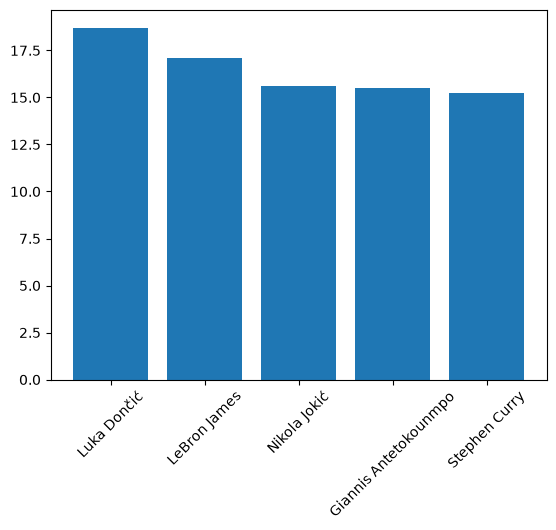

In [30]:
top5 = results_df.head(5)
top5

x = np.arange(len(top5['Player']))
plt.bar(x, top5['ALL_AROUND_SCORE'])

plt.xticks(x, top5['Player'], rotation=45)
plt.show()

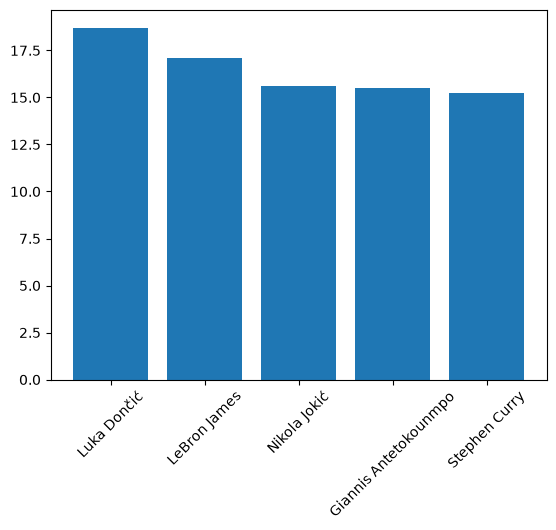

In [36]:
top5 = top5.sort_values(by='ALL_AROUND_SCORE', ascending=False)

x = np.arange(len(top5['Player']))
plt.bar(x, top5['ALL_AROUND_SCORE'])
plt.xticks(x, top5['Player'], rotation=45)
plt.show()
